# 02 · NASA POWER in 3D — seeing the variables

**Purpose.** Notebook 01 diagnosed POWER with tables and flat charts. Here the same data are shown as **interactive 3D views** to see patterns that are hard to spot in tables:
where the dry and wet years sit, when water is short, how the nine climates separate, and where the sites are on the globe.

All figures are interactive (drag to rotate, scroll to zoom, hover for values, double-click to reset) and each is also saved as a standalone HTML file in `../figures/`.
No new downloads: this notebook only uses the CSV files from notebook 01.

**Contents**
1. Setup · 2. Rainfall surface, month × year (Ipiales) · 3. Water-balance surface, P − ET0 (Ipiales) · 4. Climate space of the nine sites (annual rain × ET0 × temperature) ·
5. Rainfall climate by site and month (all sites) · 6. Globe with a switchable variable · 7. How to read these views

## 1 · Setup

In [2]:
import sys, warnings
from pathlib import Path
sys.path.append("../src")
import numpy as np, pandas as pd
import climate_tools as ct

try:
    import plotly, plotly.graph_objects as go, plotly.io as pio
except ImportError as e:
    raise ImportError("Plotly is not installed. In the terminal with the venv active run:  pip install plotly  and restart the kernel.") from e

warnings.filterwarnings("ignore")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 80)
pio.renderers.default = "plotly_mimetype"      # JupyterLab; use "browser" to open figures in a browser tab instead
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)
EMBED_PLOTLY_JS = False                         # True = self-contained HTML files (~5 MB each, work offline)

def save(fig, name):
    fig.write_html(FIG / f"{name}.html", include_plotlyjs=True if EMBED_PLOTLY_JS else "cdn")
    print("saved", FIG / f"{name}.html")

SITES = {
    "Ipiales":   (0.83,  -77.64, 2900, "tropical highland"),
    "Nairobi":   (-1.29,  36.82, 1795, "tropical highland"),
    "Sorriso":   (-12.54, -55.71, 380, "tropical savanna"),
    "Des Moines": (41.60, -93.61, 290, "humid continental"),
    "Ludhiana":  (30.90,  75.85,  247, "semi-arid irrigated"),
    "Niamey":    (13.51,   2.11,  220, "Sahel monsoon"),
    "Can Tho":   (10.03, 105.78,    2, "tropical delta"),
    "Mendoza":   (-32.89, -68.84, 750, "arid irrigated"),
    "Fallon":    (39.47, -118.78, 1240, "high desert irrigated"),
}
MAIN = "Ipiales"
DATA_DIRS = ["../data", "data", "../notebooks/data", "notebooks/data"]
data = {}
for name, (la, lo, el, _) in SITES.items():
    p = ct.find_csv(la, lo, DATA_DIRS)
    if p is None:
        raise FileNotFoundError(f"CSV for {name} not found. Run notebook 01 first (it downloads and caches the data).")
    data[name] = ct.load_csv(p)[ct.VARS]

# per-site summaries used by several figures
summ = pd.DataFrame({n: ct.site_summary(data[n], SITES[n][0], SITES[n][2]) for n in SITES}).T
for c in summ.columns:
    if c != "aridity_class": summ[c] = summ[c].astype(float)
df = data[MAIN]; LAT, LON, ELEV = SITES[MAIN][:3]
print("plotly", plotly.__version__, "| sites:", len(data), "| days per site:", len(df))

plotly 7.1.0 | sites: 9 | days per site: 9131


## 2 · Rainfall surface: month × year (Ipiales)

Height = total rain of that month in that year (mm). Each row of the surface is one year, each column one month. Ridges are wet months, valleys dry months.

saved ..\figures\3d_01_rain_surface_ipiales.html


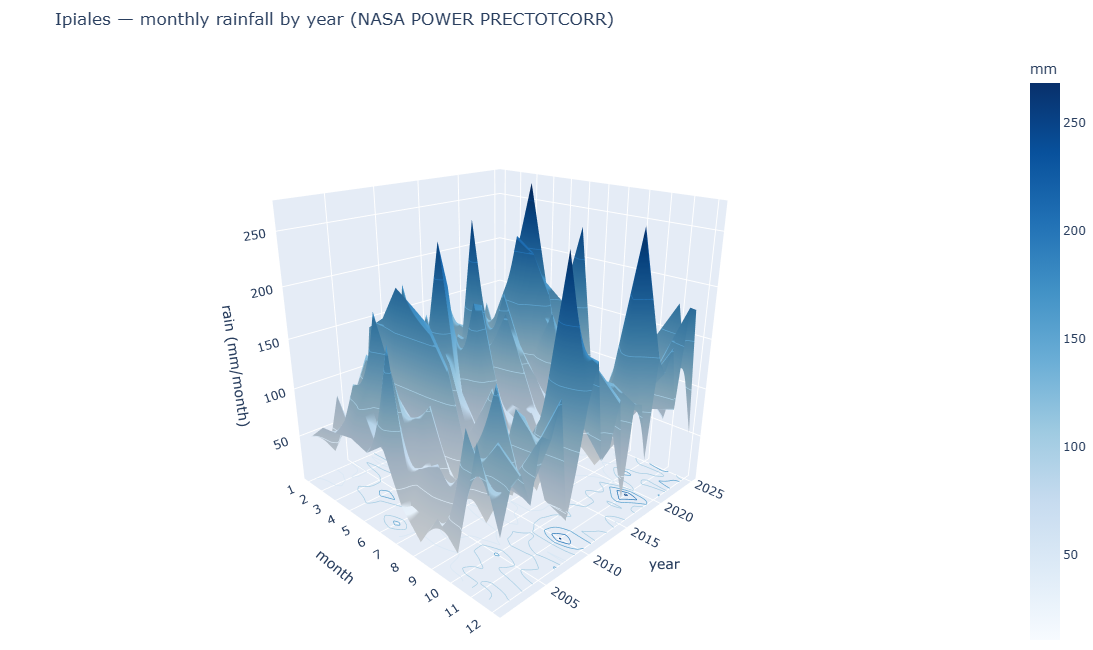

Wettest years: {2025: 1613.0, 2011: 1442.0, 2008: 1404.0}
Driest years : {2001: 737.0, 2020: 778.0, 2009: 784.0}
Wettest month on record: (np.int32(2025), np.int32(3)) 268.4 mm


In [3]:
mr = ct.monthly_series(df, "PRECTOTCORR")
rain_m = mr.groupby([mr.index.year, mr.index.month]).sum().unstack()          # rows = year, cols = month
years, months = rain_m.index.values, rain_m.columns.values

fig = go.Figure(go.Surface(
    x=months, y=years, z=rain_m.values, colorscale="Blues", colorbar=dict(title="mm"),
    contours_z=dict(show=True, usecolormap=True, project_z=True),
    hovertemplate="month %{x}<br>year %{y}<br>%{z:.0f} mm<extra></extra>"))
fig.update_layout(title="Ipiales — monthly rainfall by year (NASA POWER PRECTOTCORR)", height=650,
                  scene=dict(xaxis=dict(title="month", tickvals=list(range(1, 13))), yaxis=dict(title="year"),
                             zaxis=dict(title="rain (mm/month)"), camera=dict(eye=dict(x=1.6, y=-1.6, z=0.9))),
                  margin=dict(l=0, r=0, t=50, b=0))
save(fig, "3d_01_rain_surface_ipiales"); fig.show()

annual = rain_m.sum(axis=1)
print("Wettest years:", annual.sort_values(ascending=False).head(3).round(0).to_dict())
print("Driest years :", annual.sort_values().head(3).round(0).to_dict())
print("Wettest month on record:", rain_m.stack().idxmax(), round(rain_m.stack().max(), 1), "mm")

## 3 · Water-balance surface: P − ET0 (Ipiales)

Same layout, but the height is **rain minus reference evapotranspiration** (ET0, FAO-56 Penman–Monteith, from `climate_tools`). Above the grey plane (zero) the soil receives more water than the atmosphere demands;
below it there is a deficit. This is the view most relevant to a farmer's planning.

saved ..\figures\3d_02_water_balance_surface_ipiales.html


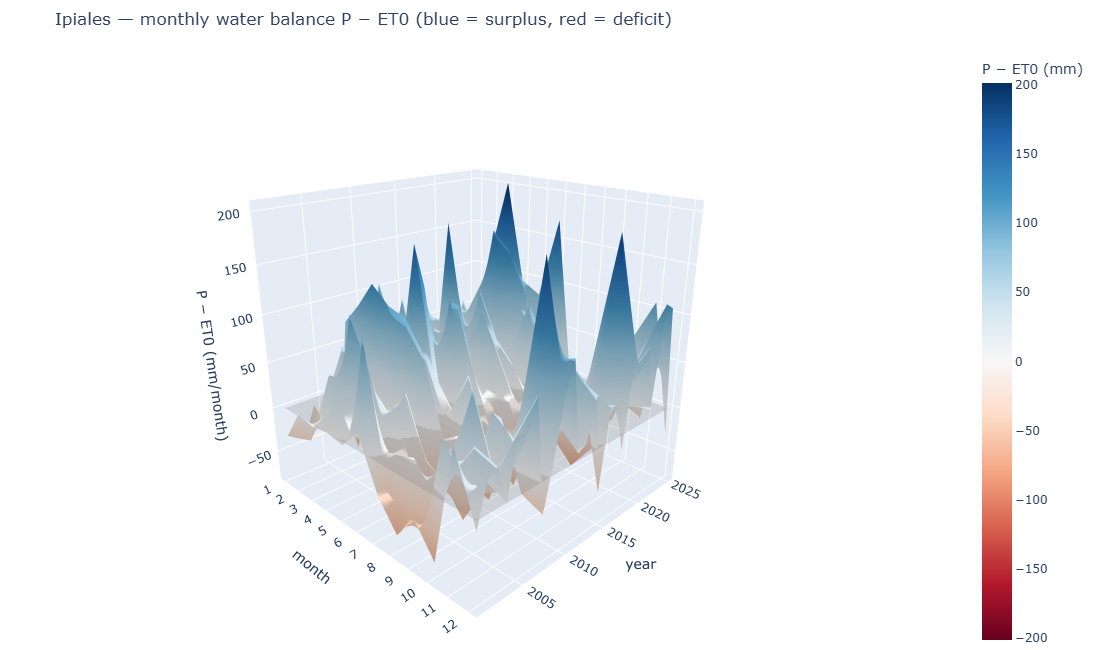

Share of years with a deficit, by month (%):
date
1     44
2     32
3     12
4     12
5     24
6     40
7     80
8     92
9     88
10    36
11    12
12    24

Most severe monthly deficit: (np.int32(2020), np.int32(9)) -74.0 mm


In [4]:
et0 = ct.et0_fao56(df, LAT, ELEV)
bal = (df.PRECTOTCORR - et0).resample("MS").sum()
bal_m = bal.groupby([bal.index.year, bal.index.month]).sum().unstack()
lim = float(np.abs(bal_m.values).max())

fig = go.Figure()
fig.add_trace(go.Surface(x=months, y=years, z=bal_m.values, colorscale="RdBu", cmid=0, cmin=-lim, cmax=lim,
                         colorbar=dict(title="P − ET0 (mm)"),
                         hovertemplate="month %{x}<br>year %{y}<br>%{z:.0f} mm<extra></extra>"))
fig.add_trace(go.Surface(x=months, y=years, z=np.zeros_like(bal_m.values), showscale=False, opacity=.25,
                         colorscale=[[0, "grey"], [1, "grey"]], hoverinfo="skip"))
fig.update_layout(title="Ipiales — monthly water balance P − ET0 (blue = surplus, red = deficit)", height=650,
                  scene=dict(xaxis=dict(title="month", tickvals=list(range(1, 13))), yaxis=dict(title="year"),
                             zaxis=dict(title="P − ET0 (mm/month)"), camera=dict(eye=dict(x=1.6, y=-1.6, z=0.9))),
                  margin=dict(l=0, r=0, t=50, b=0))
save(fig, "3d_02_water_balance_surface_ipiales"); fig.show()

share_def = 100 * (bal_m < 0).mean()
print("Share of years with a deficit, by month (%):"); print(share_def.round(0).astype(int).to_string())
print("\nMost severe monthly deficit:", bal_m.stack().idxmin(), round(bal_m.stack().min(), 0), "mm")

## 4 · Climate space of the nine sites

Each **small dot is one site-year** (25 per site); the **large labelled marker is the site's 25-year mean**.
Axes: annual rain, annual ET0 (evaporative demand) and mean temperature. Sites that sit apart are climatically different; a cloud stretched along one axis shows which variable varies most from year to year.

saved ..\figures\3d_03_climate_space_sites.html


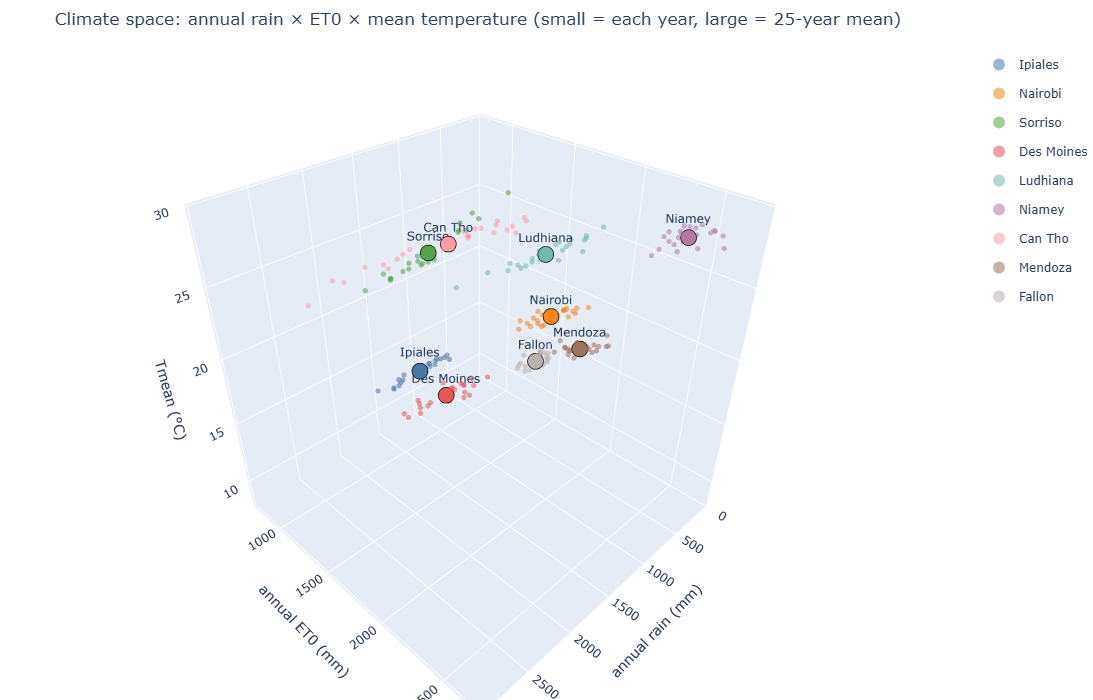

            rain_mm_yr  ET0_mm_yr  Tmean_C  P/ET0 aridity_class
Ipiales        1104.88     880.26    13.18   1.26         humid
Nairobi         580.80    1721.70    20.18   0.34     semi-arid
Sorriso        1502.37    1333.48    25.72   1.13         humid
Des Moines      856.77     955.35    10.39   0.90         humid
Ludhiana        733.46    1740.46    25.18   0.42     semi-arid
Niamey          554.99    2541.65    28.77   0.22     semi-arid
Can Tho        1604.81    1576.09    27.46   1.02         humid
Mendoza         283.33    1808.20    17.03   0.16          arid
Fallon          173.98    1382.86    13.39   0.13          arid


In [5]:
palette = ["#4c78a8", "#f58518", "#54a24b", "#e45756", "#72b7b2", "#b279a2", "#ff9da6", "#9d755d", "#bab0ac"]
fig = go.Figure()
for (n, col) in zip(SITES, palette):
    at, _ = ct.annual_table(data[n], SITES[n][0], SITES[n][2])
    fig.add_trace(go.Scatter3d(x=at.rain_mm, y=at.ET0_mm, z=at.Tmean_C, mode="markers", name=n, legendgroup=n,
                               marker=dict(size=3, color=col, opacity=.55), text=[f"{n} {y}" for y in at.index],
                               hovertemplate="%{text}<br>rain %{x:.0f} mm<br>ET0 %{y:.0f} mm<br>Tmean %{z:.1f} °C<extra></extra>"))
    fig.add_trace(go.Scatter3d(x=[at.rain_mm.mean()], y=[at.ET0_mm.mean()], z=[at.Tmean_C.mean()], mode="markers+text",
                               text=[n], textposition="top center", legendgroup=n, showlegend=False,
                               marker=dict(size=9, color=col, line=dict(color="black", width=1)),
                               hovertemplate=f"{n} (mean)<br>rain %{{x:.0f}} mm<br>ET0 %{{y:.0f}} mm<br>Tmean %{{z:.1f}} °C<extra></extra>"))
fig.update_layout(title="Climate space: annual rain × ET0 × mean temperature (small = each year, large = 25-year mean)", height=700,
                  scene=dict(xaxis=dict(title="annual rain (mm)"), yaxis=dict(title="annual ET0 (mm)"), zaxis=dict(title="Tmean (°C)")),
                  margin=dict(l=0, r=0, t=50, b=0), legend=dict(itemsizing="constant"))
save(fig, "3d_03_climate_space_sites"); fig.show()

tab = summ[["rain_mm_yr", "ET0_mm_yr", "Tmean_C", "P/ET0", "aridity_class"]].round(2)
print(tab.to_string())

## 5 · Rainfall climate by site and month

Sites on one axis (ordered from driest to wettest by P/ET0), months on the other, height = average monthly rain.
It shows at a glance which climates have a monsoon (one tall ridge), two seasons, or no season at all.

saved ..\figures\3d_04_rain_by_site_month.html


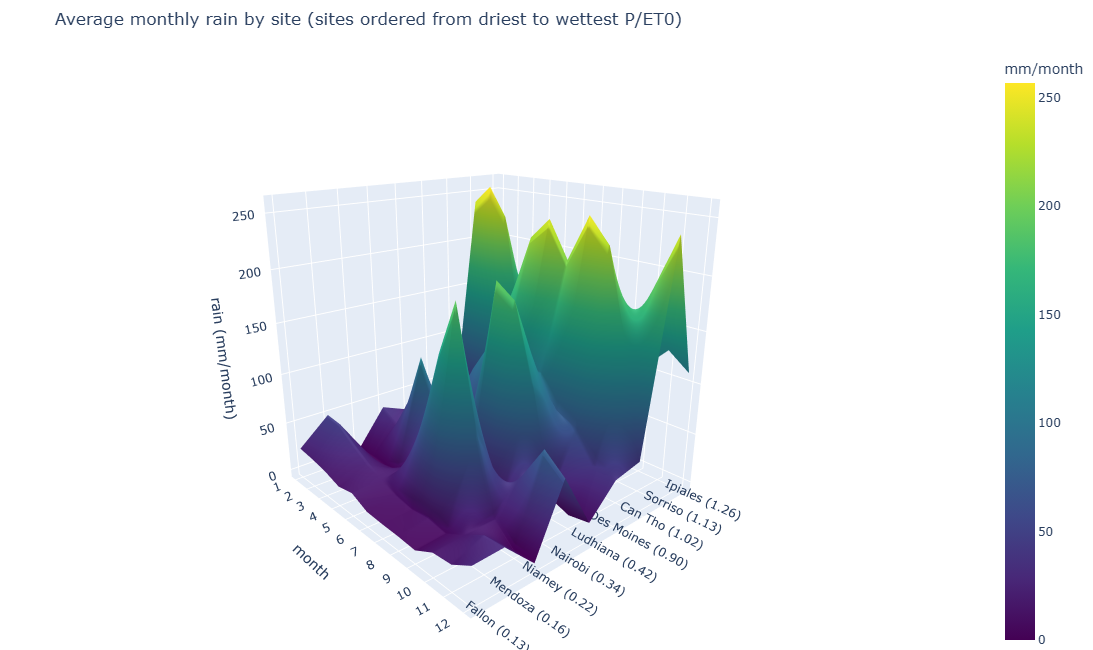

In [6]:
order = summ["P/ET0"].sort_values().index.tolist()
Z = np.array([ct.monthly_series(data[n], "PRECTOTCORR").groupby(lambda d: d.month).mean().values for n in order])
fig = go.Figure(go.Surface(x=list(range(1, 13)), y=list(range(len(order))), z=Z, colorscale="Viridis", colorbar=dict(title="mm/month"),
                           hovertemplate="month %{x}<br>%{text}<br>%{z:.0f} mm<extra></extra>",
                           text=[[n] * 12 for n in order]))
fig.update_layout(title="Average monthly rain by site (sites ordered from driest to wettest P/ET0)", height=650,
                  scene=dict(xaxis=dict(title="month", tickvals=list(range(1, 13))),
                             yaxis=dict(title="", tickvals=list(range(len(order))), ticktext=[f"{n} ({summ.loc[n,'P/ET0']:.2f})" for n in order]),
                             zaxis=dict(title="rain (mm/month)"), camera=dict(eye=dict(x=1.7, y=-1.5, z=0.8))),
                  margin=dict(l=0, r=0, t=50, b=0))
save(fig, "3d_04_rain_by_site_month"); fig.show()

## 6 · Globe with a switchable variable

Drag to rotate the globe (scroll to zoom). Use the menu to colour the nine sites by a different indicator.
Values are the 25-year POWER summaries from notebook 01 (each point is a ~55–110 km cell, not a farm).

saved ..\figures\3d_05_globe_sites.html


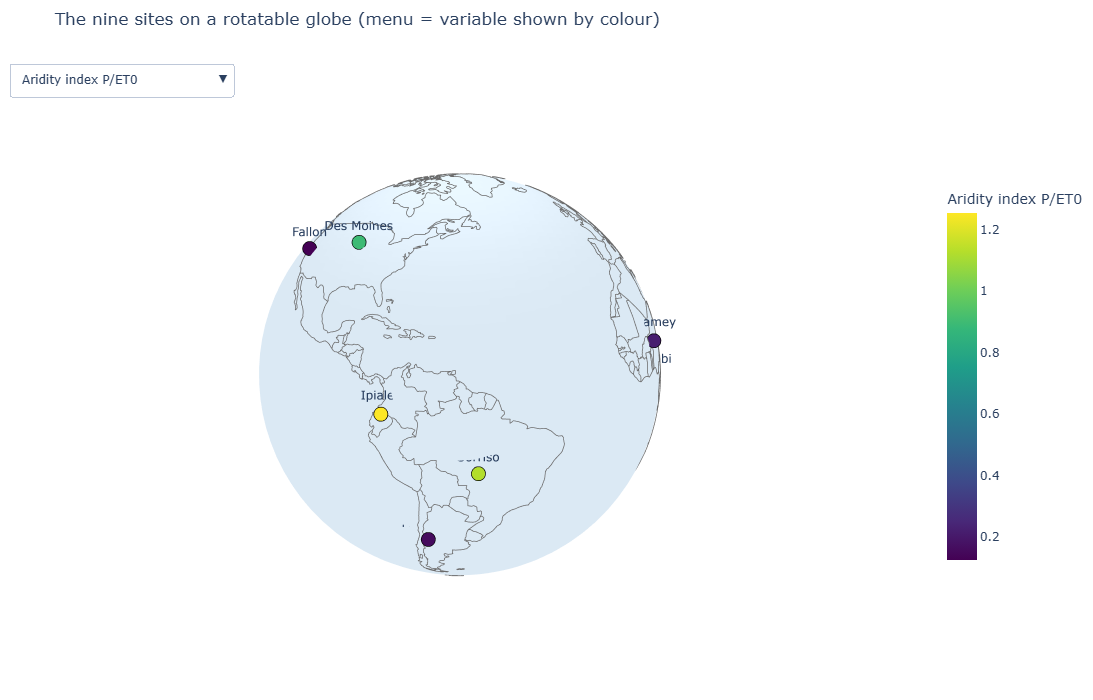

In [7]:
VARS_MAP = {
    "Aridity index P/ET0":             ("P/ET0", "Viridis"),
    "Annual rain (mm)":                ("rain_mm_yr", "Blues"),
    "Annual ET0 (mm)":                 ("ET0_mm_yr", "YlOrRd"),
    "Mean temperature (°C)":           ("Tmean_C", "RdYlBu_r"),
    "Frost days/yr (Tmin ≤ 2 °C)":     ("frost_days_Tmin<=2C_yr", "PuBu"),
    "Rain variability, CV (%)":        ("rain_CV_%", "Oranges"),
    "Seasonal range of Tmean (°C)":    ("seasonal_range_Tmean_C", "Magma"),
}
import json
def xyz(lat, lon, r=1.0):
    la, lo = np.radians(np.asarray(lat, float)), np.radians(np.asarray(lon, float))
    return r*np.cos(la)*np.cos(lo), r*np.cos(la)*np.sin(lo), r*np.sin(la)

# country outlines (Natural Earth, public domain) stored locally so the globe works offline
outline = None
for d in DATA_DIRS:
    f = Path(d) / "world_outline.json"
    if f.exists(): outline = json.load(open(f)); break

names = list(summ.index)
lat = [SITES[n][0] for n in names]; lon = [SITES[n][1] for n in names]
x, y, z = xyz(lat, lon, 1.02)
first = list(VARS_MAP)[0]; col0, cs0 = VARS_MAP[first]

fig = go.Figure()
# ocean sphere
u, v = np.meshgrid(np.linspace(0, 2*np.pi, 90), np.linspace(-np.pi/2, np.pi/2, 45))
fig.add_trace(go.Surface(x=np.cos(v)*np.cos(u), y=np.cos(v)*np.sin(u), z=np.sin(v), showscale=False,
                         colorscale=[[0, "#dbe9f4"], [1, "#dbe9f4"]], lighting=dict(ambient=1, diffuse=0), hoverinfo="skip"))
if outline:
    ox, oy, oz = xyz([np.nan if q is None else q for q in outline["lat"]], [np.nan if q is None else q for q in outline["lon"]], 1.003)
    fig.add_trace(go.Scatter3d(x=ox, y=oy, z=oz, mode="lines", line=dict(color="#6b6b6b", width=1.5), hoverinfo="skip", showlegend=False))
else:
    print("world_outline.json not found: showing the sphere without continents")
fig.add_trace(go.Scatter3d(x=x, y=y, z=z, mode="markers+text", text=names, textposition="top center", showlegend=False,
                           marker=dict(size=8, color=summ[col0], colorscale=cs0, line=dict(color="black", width=1),
                                       colorbar=dict(title=first, len=.6)),
                           customdata=np.c_[summ["aridity_class"], summ["rain_mm_yr"], summ["ET0_mm_yr"], summ["Tmean_C"]],
                           hovertemplate="<b>%{text}</b><br>%{customdata[0]}<br>rain %{customdata[1]:.0f} mm | ET0 %{customdata[2]:.0f} mm<br>Tmean %{customdata[3]:.1f} °C<extra></extra>"))
idx = len(fig.data) - 1
buttons = [dict(label=k, method="restyle",
                args=[{"marker.color": [summ[c].tolist()], "marker.colorscale": [cs], "marker.colorbar.title.text": k}, [idx]])
           for k, (c, cs) in VARS_MAP.items()]
cam_lat, cam_lon = np.radians(10), np.radians(-60)
fig.update_layout(title="The nine sites on a rotatable globe (menu = variable shown by colour)", height=700, margin=dict(l=0, r=0, t=50, b=0),
                  updatemenus=[dict(buttons=buttons, direction="down", x=0.01, y=0.98, xanchor="left", yanchor="top")],
                  scene=dict(xaxis=dict(visible=False), yaxis=dict(visible=False), zaxis=dict(visible=False), aspectmode="data",
                             camera=dict(eye=dict(x=1.9*np.cos(cam_lat)*np.cos(cam_lon), y=1.9*np.cos(cam_lat)*np.sin(cam_lon), z=1.9*np.sin(cam_lat)))))
save(fig, "3d_05_globe_sites"); fig.show()

## 7 · How to read these views

* **Rainfall surface (Section 2).** Rows are years, columns are months. Two ridges per year (around April and November) are the two rainy seasons; the valley in July–September is the dry season.
  Years with higher ridges are the wet years; low ridges are the dry years. The printed lists give the exact years and values.
* **Water-balance surface (Section 3).** Blue above the grey plane = more rain than the atmosphere demands; red below it = deficit. The printed table gives the share of years with a deficit in each month.
* **Climate space (Section 4).** Distance between the large markers is climatic difference. Each site's cloud shows how much its years vary: in humid tropical sites the cloud stretches mainly along the rain axis,
  because evaporative demand (ET0) and temperature barely change from year to year.
* **Rain by site and month (Section 5).** One tall ridge = a single monsoon (Niamey, Ludhiana); a flat low sheet = little rain at any time of year (Fallon, Mendoza).
* **Globe (Section 6).** Use the menu to see which sites are humid or arid, cold or hot, frost-prone or not, and how variable their rain is.

**Limits.** These are POWER cells of ~55–110 km; a 3D view of a coarse product does not add resolution. Features smaller than a cell (valleys, slopes, microclimates) are not visible.
Terrain-based 3D (elevation model with the data draped on it) needs a finer source and is planned once IMERG and elevation data are added.